In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
loans = pd.read_csv(r"C:\Python Learning\Python Learning\loan.csv")
loans.head()

C:\Users\C15556E\AppData\Local\Temp\ipykernel_52696\170108555.py:1: DtypeWarning: Columns (0: desc, 1: next_pymnt_d, 2: verification_status_joint, 3: sec_app_earliest_cr_line, 4: hardship_type, 5: hardship_reason, 6: hardship_status, 7: hardship_start_date, 8: hardship_end_date, 9: payment_plan_start_date, 10: hardship_loan_status, 11: debt_settlement_flag_date, 12: settlement_status, 13: settlement_date) have mixed types. Specify dtype option on import or set low_memory=False.
  loans = pd.read_csv(r"C:\Python Learning\Python Learning\loan.csv")


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,NaN,NaN,2500,2500,2500.0,36 months,13.56,84.92,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,30000,30000,30000.0,60 months,18.94,777.23,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,5000,5000,5000.0,36 months,17.97,180.69,D,D1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,4000,4000,4000.0,36 months,18.94,146.51,D,D2,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,30000,30000,30000.0,60 months,16.14,731.78,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
loans.shape

(2260668, 145)

In [5]:

pd.set_option('display.max_columns', None)
print(list(loans.columns))

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_i

Filtering out only active loans and keeping only the paid and defaulted loans

In [6]:
loans['mort_acc'].unique()

array([ 0.,  3.,  2.,  6.,  1.,  4.,  5.,  9.,  8.,  7., 10., 12., 11.,
       14., 13., 15., 16., 17., 32., 18., 87., 24., 23., 20., 19., 21.,
       25., 22., 31., 46., 30., 45., 29., 26., 37., 28., 51., 27., 61.,
       35., 47., 52., 34., 33., 41., 94., nan, 36.])

In [7]:
status = ['Fully Paid','Default','Charged Off']
loans = loans[loans['loan_status'].isin(status)]
loans.shape

(1303638, 145)

Removing all the unnecessary columns and keeping only those columns that are considered as a factor before approving a loan.

In [8]:
cols = ['loan_amnt','grade','sub_grade','emp_title','emp_length','home_ownership','annual_inc','verification_status','purpose','zip_code','addr_state',
        'dti','pub_rec','total_acc','application_type','mort_acc','tax_liens','loan_status']

loans = loans[cols]
print(loans.shape)
loans.head()


(1303638, 18)


,loan_amnt,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,purpose,zip_code,addr_state,dti,pub_rec,total_acc,application_type,mort_acc,tax_liens,loan_status
100,30000,D,D5,Supervisor,5 years,MORTGAGE,100000.0,Source Verified,debt_consolidation,917xx,CA,30.46,1.0,19.0,Joint App,1.0,0.0,Fully Paid
152,40000,C,C4,Assistant to the Treasurer (Payroll),< 1 year,MORTGAGE,45000.0,Verified,credit_card,456xx,OH,50.53,0.0,37.0,Joint App,1.0,0.0,Fully Paid
170,20000,A,A3,Teacher,10+ years,MORTGAGE,100000.0,Not Verified,credit_card,982xx,WA,18.92,0.0,19.0,Joint App,5.0,0.0,Fully Paid
186,4500,B,B3,Accounts Examiner III,10+ years,RENT,38500.0,Not Verified,credit_card,786xx,TX,4.64,0.0,25.0,Individual,0.0,0.0,Fully Paid
215,8425,E,E5,Senior Director Risk Management,3 years,MORTGAGE,450000.0,Verified,credit_card,020xx,MA,12.37,0.0,37.0,Joint App,4.0,0.0,Fully Paid


In [9]:
loans.info()

<class 'pandas.DataFrame'>
Index: 1303638 entries, 100 to 2260664
Data columns (total 18 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   loan_amnt            1303638 non-null  int64  
 1   grade                1303638 non-null  str    
 2   sub_grade            1303638 non-null  str    
 3   emp_title            1221056 non-null  str    
 4   emp_length           1228181 non-null  str    
 5   home_ownership       1303638 non-null  str    
 6   annual_inc           1303638 non-null  float64
 7   verification_status  1303638 non-null  str    
 8   purpose              1303638 non-null  str    
 9   zip_code             1303637 non-null  str    
 10  addr_state           1303638 non-null  str    
 11  dti                  1303326 non-null  float64
 12  pub_rec              1303638 non-null  float64
 13  total_acc            1303638 non-null  float64
 14  application_type     1303638 non-null  str    
 15  mort_acc    

Handling Null Values

In [10]:
loans['emp_title']=loans['emp_title'].fillna('Unknown')
loans['emp_length']=loans['emp_length'].fillna('Unknown')
loans['zip_code']=loans['zip_code'].fillna('Unknown') 
loans['dti']=loans['dti'].fillna(loans['dti'].median())   
loans['mort_acc']=loans['mort_acc'].fillna(0) 
loans['tax_liens']=loans['tax_liens'].fillna(0) 

In [11]:
loans.info()

<class 'pandas.DataFrame'>
Index: 1303638 entries, 100 to 2260664
Data columns (total 18 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   loan_amnt            1303638 non-null  int64  
 1   grade                1303638 non-null  str    
 2   sub_grade            1303638 non-null  str    
 3   emp_title            1303638 non-null  str    
 4   emp_length           1303638 non-null  str    
 5   home_ownership       1303638 non-null  str    
 6   annual_inc           1303638 non-null  float64
 7   verification_status  1303638 non-null  str    
 8   purpose              1303638 non-null  str    
 9   zip_code             1303638 non-null  str    
 10  addr_state           1303638 non-null  str    
 11  dti                  1303638 non-null  float64
 12  pub_rec              1303638 non-null  float64
 13  total_acc            1303638 non-null  float64
 14  application_type     1303638 non-null  str    
 15  mort_acc    

In [12]:
loans['loan_status'] = np.where(loans['loan_status']=='Fully Paid',0,1)
loans.head()

,loan_amnt,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,purpose,zip_code,addr_state,dti,pub_rec,total_acc,application_type,mort_acc,tax_liens,loan_status
100,30000,D,D5,Supervisor,5 years,MORTGAGE,100000.0,Source Verified,debt_consolidation,917xx,CA,30.46,1.0,19.0,Joint App,1.0,0.0,0
152,40000,C,C4,Assistant to the Treasurer (Payroll),< 1 year,MORTGAGE,45000.0,Verified,credit_card,456xx,OH,50.53,0.0,37.0,Joint App,1.0,0.0,0
170,20000,A,A3,Teacher,10+ years,MORTGAGE,100000.0,Not Verified,credit_card,982xx,WA,18.92,0.0,19.0,Joint App,5.0,0.0,0
186,4500,B,B3,Accounts Examiner III,10+ years,RENT,38500.0,Not Verified,credit_card,786xx,TX,4.64,0.0,25.0,Individual,0.0,0.0,0
215,8425,E,E5,Senior Director Risk Management,3 years,MORTGAGE,450000.0,Verified,credit_card,020xx,MA,12.37,0.0,37.0,Joint App,4.0,0.0,0


BASELINE DEFAULT RATE

In [13]:
default_rate = loans['loan_status'].mean()*100
default_rate

np.float64(20.073517341470563)

Above rate represents that out of 100 loans that were approved, 20 loans result in default. 1 in every 5 loans are default.
Hence, 20% is the benchmark rate of default.

Loan Default by Income

In [14]:
loans['annual_inc'].describe().apply(lambda x: f"{x:,.2f}")

count     1,303,638.00
mean         76,158.75
std          70,048.27
min               0.00
25%          45,840.00
50%          65,000.00
75%          90,000.00
max      10,999,200.00
Name: annual_inc, dtype: str

GROUPING RECORDS INTO DIFFERENT INCOME CATEGORIES

In [15]:
loans[loans['annual_inc']<10000].count()

loan_amnt              1383
grade                  1383
sub_grade              1383
emp_title              1383
emp_length             1383
home_ownership         1383
annual_inc             1383
verification_status    1383
purpose                1383
zip_code               1383
addr_state             1383
dti                    1383
pub_rec                1383
total_acc              1383
application_type       1383
mort_acc               1383
tax_liens              1383
loan_status            1383
dtype: int64

In [16]:
condition = [(loans['annual_inc']<10000), (loans['annual_inc']<40000),(loans['annual_inc']<60000),(loans['annual_inc']<=90000),
(loans['annual_inc']< loans['annual_inc'].max())]

choice = ['Ultra_low(<10k)','Low(10k-40k)','Lower_Middle_class(40k-60k)', 'Upper_middle(60k-90k)','High(>90k)']

loans['Income_group'] = np.select(condition, choice, default='Unknown')
loans

,loan_amnt,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,purpose,zip_code,addr_state,dti,pub_rec,total_acc,application_type,mort_acc,tax_liens,loan_status,Income_group
100,30000,D,D5,Supervisor,5 years,MORTGAGE,100000.0,Source Verified,debt_consolidation,917xx,CA,30.46,1.0,19.0,Joint App,1.0,0.0,0,High(>90k)
152,40000,C,C4,Assistant to the Treasurer (Payroll),< 1 year,MORTGAGE,45000.0,Verified,credit_card,456xx,OH,50.53,0.0,37.0,Joint App,1.0,0.0,0,Lower_Middle_class(40k-60k)
170,20000,A,A3,Teacher,10+ years,MORTGAGE,100000.0,Not Verified,credit_card,982xx,WA,18.92,0.0,19.0,Joint App,5.0,0.0,0,High(>90k)
186,4500,B,B3,Accounts Examiner III,10+ years,RENT,38500.0,Not Verified,credit_card,786xx,TX,4.64,0.0,25.0,Individual,0.0,0.0,0,Low(10k-40k)
215,8425,E,E5,Senior Director Risk Management,3 years,MORTGAGE,450000.0,Verified,credit_card,020xx,MA,12.37,0.0,37.0,Joint App,4.0,0.0,0,High(>90k)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2260654,30000,D,D1,Senior Manager,2 years,RENT,80000.0,Not Verified,debt_consolidation,112xx,NY,23.22,0.0,69.0,Individual,0.0,0.0,1,Upper_middle(60k-90k)
2260655,18000,F,F4,Package Delivery Driver,10+ years,MORTGAGE,77000.0,Verified,debt_consolidation,799xx,TX,8.08,0.0,15.0,Individual,1.0,0.0,1,Upper_middle(60k-90k)
2260656,17950,F,F3,Head Custodian,10+ years,MORTGAGE,53758.0,Source Verified,debt_consolidation,600xx,IL,33.24,1.0,24.0,Individual,3.0,0.0,0,Lower_Middle_class(40k-60k)
2260658,15000,C,C5,Instructional Designer,< 1 year,RENT,85000.0,Verified,debt_consolidation,119xx,NY,14.66,0.0,87.0,Individual,1.0,0.0,0,Upper_middle(60k-90k)


In [17]:
loan_by_income_default = loans.groupby('Income_group', as_index = True)['loan_status'].mean()*100
loan_by_income_default

Income_group
High(>90k)                     16.252727
Low(10k-40k)                   23.934076
Lower_Middle_class(40k-60k)    21.808002
Ultra_low(<10k)                23.788865
Unknown                         0.000000
Upper_middle(60k-90k)          19.727206
Name: loan_status, dtype: float64

CHI SQUARE TEST ON INCOME AND LOAN STATUS

In [18]:
from scipy.stats import chi2_contingency

contigency_table = pd.crosstab(loans['Income_group'],loans['loan_status'])

income_chi_2, income_p_value,dof,expected = chi2_contingency(contigency_table)
print(income_p_value)
print(income_chi_2)

0.0
5509.534963254723


DEBT TO INCOME RATIO

In [19]:
loans['dti'].describe().apply(lambda x: f"{x:,.2f}")

count    1,303,638.00
mean            18.26
std             10.94
min             -1.00
25%             11.79
50%             17.61
75%             24.04
max            999.00
Name: dti, dtype: str

A negative dti is not possible,hence it is a data entry issue. DTI of 999 is practically impossible as it means a person is paying 10x of income as debt.

In [20]:
condition_1 = [(loans['dti']<0),(loans['dti']<12),(loans['dti']<20),(loans['dti']<35),(loans['dti']<=loans['dti'].max())
]
choice_1 = ['Data_error','Low debt(0-12)','Moderate Debt(12-20)','High Debt(20-35)','Severe Debt(>35)']

loans['dti_group'] = np.select(condition_1,choice_1,'Unknown')

loan_by_dti_default = loans.groupby('dti_group',as_index = True)['loan_status'].mean()*100
loan_by_dti_default
            


dti_group
Data_error               0.000000
High Debt(20-35)        24.228874
Low debt(0-12)          15.196687
Moderate Debt(12-20)    18.366312
Severe Debt(>35)        31.490999
Name: loan_status, dtype: float64

CHI SQUARE TEST ON DTI AND LOAN STATUS

In [21]:
from scipy.stats import chi2_contingency

contigency_table = pd.crosstab(loans['dti_group'],loans['loan_status'])

dti_chi_2, dti_p_value,dof,expected = chi2_contingency(contigency_table)
print(dti_p_value)
print(dti_chi_2)

0.0
13738.547320364429


Loan Default by Grade

In [22]:
loan_default_by_grade = loans.groupby('grade',as_index = True)['loan_status'].mean()*100
loan_default_by_grade

grade
A     6.085438
B    13.437308
C    22.509508
D    30.441707
E    38.622316
F    45.307289
G    50.072618
Name: loan_status, dtype: float64

In [23]:
from scipy.stats import chi2_contingency

contigency_table = pd.crosstab(loans['grade'],loans['loan_status'])

grade_chi_2, grade_p_value,dof,expected = chi2_contingency(contigency_table)
print(grade_p_value)
print(grade_chi_2)


0.0
89633.826799807


HOW INCOME AND DEBT TO INCOME TOGETHER DRIVES TO LOAN DEFAULT

In [24]:
matrix = loans.pivot_table(values='loan_status' ,index='Income_group', columns='dti_group',aggfunc='mean')*100
ordered_matrix = matrix.reindex(choice)
ordered_matrix.round(2)

dti_group,Data_error,High Debt(20-35),Low debt(0-12),Moderate Debt(12-20),Severe Debt(>35)
Income_group,,,,,
Ultra_low(<10k),NaN,25.60,19.75,23.44,24.38
Low(10k-40k),NaN,26.41,19.20,22.05,31.58
Lower_Middle_class(40k-60k),NaN,25.18,16.36,19.62,32.48
Upper_middle(60k-90k),0.0,23.85,15.05,18.01,31.60
High(>90k),0.0,20.79,13.16,15.91,27.64


CHI SQUARE TEST - To check whether income of an applicant and dti together drives the loan default


In [25]:
from scipy.stats import chi2_contingency

contigency_table = pd.crosstab(loans['Income_group'], loans['dti_group'])

chi_2, p_value, dof, expected = chi2_contingency(contigency_table)
print('chi_2:',chi_2)
print('p_value:',p_value)


chi_2: 57529.30663227963
p_value: 0.0


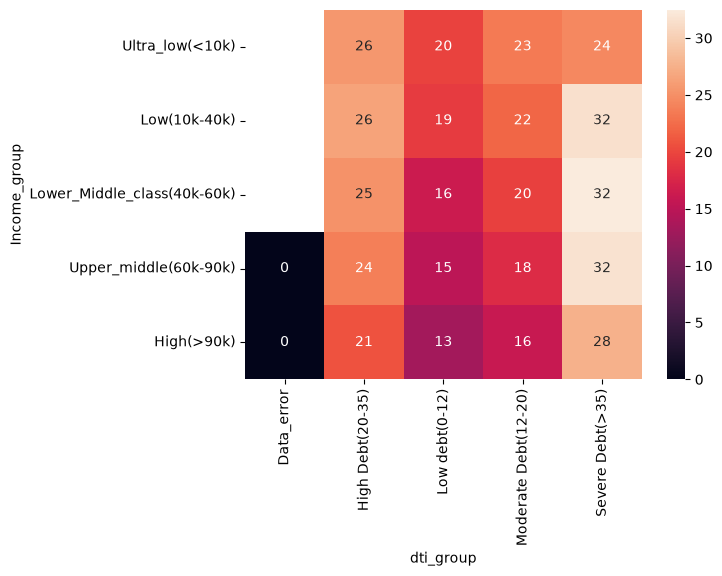

In [30]:
sns.heatmap(ordered_matrix, annot= True)
plt.show()

EMPLOYMENT LENGTH

In [ ]:
loans['emp_length'].unique()

<StringArray>
[  '5 years',  '< 1 year', '10+ years',   '3 years',   '4 years',    '1 year',
   '8 years',   'Unknown',   '2 years',   '6 years',   '9 years',   '7 years']
Length: 12, dtype: str

In [ ]:
loan_default_by_emp_length = loans.groupby('emp_length',as_index=True)['loan_status'].mean()*100
loan_default_by_emp_length 

emp_length
1 year       20.649408
10+ years    18.885179
2 years      19.929557
3 years      20.092319
4 years      19.896710
5 years      19.696654
6 years      19.462041
7 years      19.579349
8 years      20.065283
9 years      20.022624
< 1 year     20.680618
Unknown      27.031289
Name: loan_status, dtype: float64

In [ ]:
contigency_table = pd.crosstab(loans['emp_length'],loans['loan_status'])

empl_chi_2, emp_p_value, dof,expected = chi2_contingency(contigency_table)
print('empl_chi_2:',empl_chi_2)
print('emp_p_value:',emp_p_value)

empl_chi_2: 2729.1569235031757
emp_p_value: 0.0


Almost most of the employement length is close to the benchmark, except the Unknown one which is 7% higher than the benchmark. A 0 p-value indicates that it is statisitcally significant even when most of the meployment length is close to the benchmark. This is because the sample size is huge which in turn converts even a minor gap as huge driving factor.
Secondly, since the variance(max and min) between each category is 9%, we can conclude that employment length is statistically significant and is a driving factor for loan default.
Applicants having 'Unknown' employment length could ideally mean freelancers, unemployed or people who is hiding their employment length. This particular group is of high risk and banks should be avoid or be very cautious while approving the loans.


Applicants omitting employment data ("Unknown" group) explode to a 27.03% default rate, revealing omission itself is an active risk signal. It is just this category that is causing a correlation between loan default and employment length.


HOME OWNERSHIP

In [ ]:
v = loans[(loans['home_ownership']=='OTHER') | (loans['home_ownership']=='ANY') | (loans['home_ownership']=='NONE')]
print(v.shape)
loans['home_ownership'] = loans['home_ownership'].replace({'OTHER':'UNKNOWN','ANY':'UNKNOWN','NONE':'UNKNOWN'})

(459, 20)


In [ ]:
loan_default_by_home_ownership = loans.groupby('home_ownership',as_index=True)['loan_status'].mean()*100
loan_default_by_home_ownership

home_ownership
MORTGAGE    17.300301
OWN         20.748093
RENT        23.349574
UNKNOWN     18.736383
Name: loan_status, dtype: float64

In [ ]:
v = loans[(loans['home_ownership']=='OTHER') | (loans['home_ownership']=='ANY') | (loans['home_ownership']=='NONE')]
v.shape

(0, 20)

In [ ]:
contigency_table = pd.crosstab(loans['home_ownership'],loans['loan_status'])

home_chi_2, home_p_value, dof,expected = chi2_contingency(contigency_table)
print('home_chi_2:',home_chi_2)
print('home_p_value:',home_p_value)

home_chi_2: 6598.352421709291
home_p_value: 0.0


Homeownership also indicates that it is statistically significant as the pvalue is 0 and the range of variance(risk gap) is 9%. Applicants who have rented their house are on high risk of default whereas those who have mortgages are the less riskier ones. Ones with mortgages would generally be the ones who are stable as they've got the mortgage after checking all their financial credibility or strict screening by banks. Chi_2 value is also high confirming the risk gap is solid.



LOAN PURPOSE

In [ ]:
loan_default_by_purpose = loans.groupby('purpose',as_index=True)['loan_status'].mean()*100
loan_default_by_purpose

purpose
car                   14.644855
credit_card           17.027875
debt_consolidation    21.258695
educational           17.177914
home_improvement      17.855072
house                 21.716664
major_purchase        18.723524
medical               21.911608
moving                23.449253
other                 21.173786
renewable_energy      23.710209
small_business        29.746835
vacation              19.239579
wedding               12.162162
Name: loan_status, dtype: float64

In [ ]:
contigency_table = pd.crosstab(loans['purpose'],loans['loan_status'])

purpose_chi_2, purpose_p_value, dof,expected = chi2_contingency(contigency_table)
print('purpose_chi_2:',purpose_chi_2)
print('purpose_p_value:',purpose_p_value)

purpose_chi_2: 4008.8375719206183
purpose_p_value: 0.0


Loan purpose is also a statistically and practically significant factor for the business as the range of variance is huge. Small business owneres have huge risk of defaulting. Loans for wedding and car are much safer options as the risk of defaulting is less. Debt consolidation sits right above the baseline giving moderate range of risk.

Lending Club should either implement a strict cap on maximum amounts for small_business loans or automatically load them with premium interest rates. Conversely, they should aggressively market toward wedding and car loans.


TOTAL CREDIT LINES THAT APPLICANT HAD/HAVE 

In [ ]:
loans['total_acc'].describe().apply(lambda x: f"{x:,.2f}")

count    1,303,638.00
mean            25.02
std             12.00
min              2.00
25%             16.00
50%             23.00
75%             32.00
max            176.00
Name: total_acc, dtype: str

In [ ]:
condition_2 = [loans['total_acc']< 17,loans['total_acc']< 25,loans['total_acc']< 40,loans['total_acc']<= loans['total_acc'].max()]
choice_2 = [('credit < 17'),('credit < 25'),('credit < 40'),('credit <= 176')]

loans['no_of_credit_lines'] = np.select(condition_2,choice_2,'Unknown')

In [ ]:
loan_default_by_total_acc = loans.groupby('no_of_credit_lines',as_index=True)['loan_status'].mean()*100
loan_default_by_total_acc

no_of_credit_lines
credit < 17      21.107507
credit < 25      20.005036
credit < 40      19.432021
credit <= 176    19.830569
Name: loan_status, dtype: float64

~1% to 1.68% variance across stated values.
Business Verdict: No Practical Significance for Core Underwriting.  Total number of accounts completely flatten out right at the 20% baseline benchmark.


Strategic Corporate Policy Recommendations

1. Restrict or Premium-Price Small Business Loans: Implement strict maximum lending limits on loans categorized under small_business intent, or load them with premium interest rates to counteract the steep 29.75% default pattern.
2. Incentivize Safe Sub-Portfolios: Aggressively market and offer discounted pricing to applicants borrowing for specific, low-risk use cases like wedding and car loans, as well as those holding a MORTGAGE.
3. Enact a Hard Floor on Income and DTI: Implement mandatory auto-rejections for applicants presenting an annual income under 10,000 or a DTI over 35.
4. Mandate Stated Attributes: Convert the emp_length input field from an optional text string to a mandatory verified selection to eliminate the high-risk 27% default loop caused by data omission.